<a href="https://colab.research.google.com/github/mariomartinez1313-ship-it/ProyectoP1-GrupoC/blob/main/ProyectoP1_ELNO4_2_GrupoC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Parcial I: Predicción del rendimiento académico
**Materia:** Aprendizaje Automático  
**Paralelo:** CDIA - ELNO - 4/2, CI 2026-2027  
**Grupo:** C  
**Fecha:** 25 de noviembre de 2026  

**Integrantes**
- Alcívar Zambrano Derian Esneyder
- Carvajal Guerra Britanie Brigithe
- Cassagne Morales Ricardo Paul
- Correa Tandazo Richard Samuel
- Martínez Ibáñez Mario Fernando
- Sancán Pérez Andre Alejandro

# Parte 1. Análisis exploratorio de datos (EDA)
1.- Carga el dataset y describe su estructura: filas, columnas, tipos de variables y estadísticas descriptivas.

Usamos el archivo student-mat.csv, que corresponde al curso de Matemáticas.

En esta parte cargamos las librerías que usaremos

In [6]:
# Librerías de datos y gráficos
import numpy as np                 # para cálculos numéricos
import pandas as pd                # para tablas de datos
import matplotlib.pyplot as plt    # para gráficos
import seaborn as sns              # para gráficos estadísticos


En esta parte leemos el archivo desde nuestro repositorio guardado en GitHub.

Aquí ejecutamos el código para revisar cuántas filas y columnas tiene la data del archivo cargado y mostrar las primeras cinco filas.

In [7]:
# Leemos el archivo desde nuestro repositorio de GitHub
url = "https://raw.githubusercontent.com/mariomartinez1313-ship-it/ProyectoP1-GrupoC/main/student-mat.csv"
df = pd.read_csv(url)

print("Filas y columnas:", df.shape)
df.head()  # muestra las 5 primeras filas

Filas y columnas: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


En esta parte revisamos el nombre y el tipo de dato de cada columna.

In [8]:
# Tipo de dato de cada columna: int es número y str u object es texto
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

En este dataset se puede visualizar que tiene listado 395 estudiantes y 33 variables. Hay 16 variables numéricas y 17 de texto. Todas las columnas tienen datos, por lo que nos asegura que no se ven valores faltantes y estarían completos.


En la siguiente parte se calcula cantidad, promedio, desviación, mínimo, cuartiles y máximo de las variables numéricas.

In [9]:
# Estadísticas de las variables numéricas
# Consideramos usar 2 decimales
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0


Al desplegar la tabla podemos ver que la nota final G3 tiene un promedio de 10.42 sobre 20 y una mediana de 11. La nota más baja es 0 y la más alta es 20.
Sin embargo, nos llama la atención la variable absences: el promedio es de 5.71 ausencias, pero existe un máximo de 75.

Ahora revisamos las variables de texto para conocer cuántas categorías tienen y cuál se repite más.

In [10]:
# Resumen de las variables de texto
df.describe(exclude="number").T

,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344


En las variables de texto podemos observar su estadística, siendo lo más relevante que la mayoría pertenece al TOP GP de escuelas el son 349. Además que la mayor parte de estudiantes son mujeres sinedo 208 de sexo F.

# 2. Grafica la distribución de G3 y la de al menos tres variables que consideres relevantes.

En esta parte realizamos el código para graficar la nota final, las reprobaciones previas, el tiempo de estudio y las ausencias.

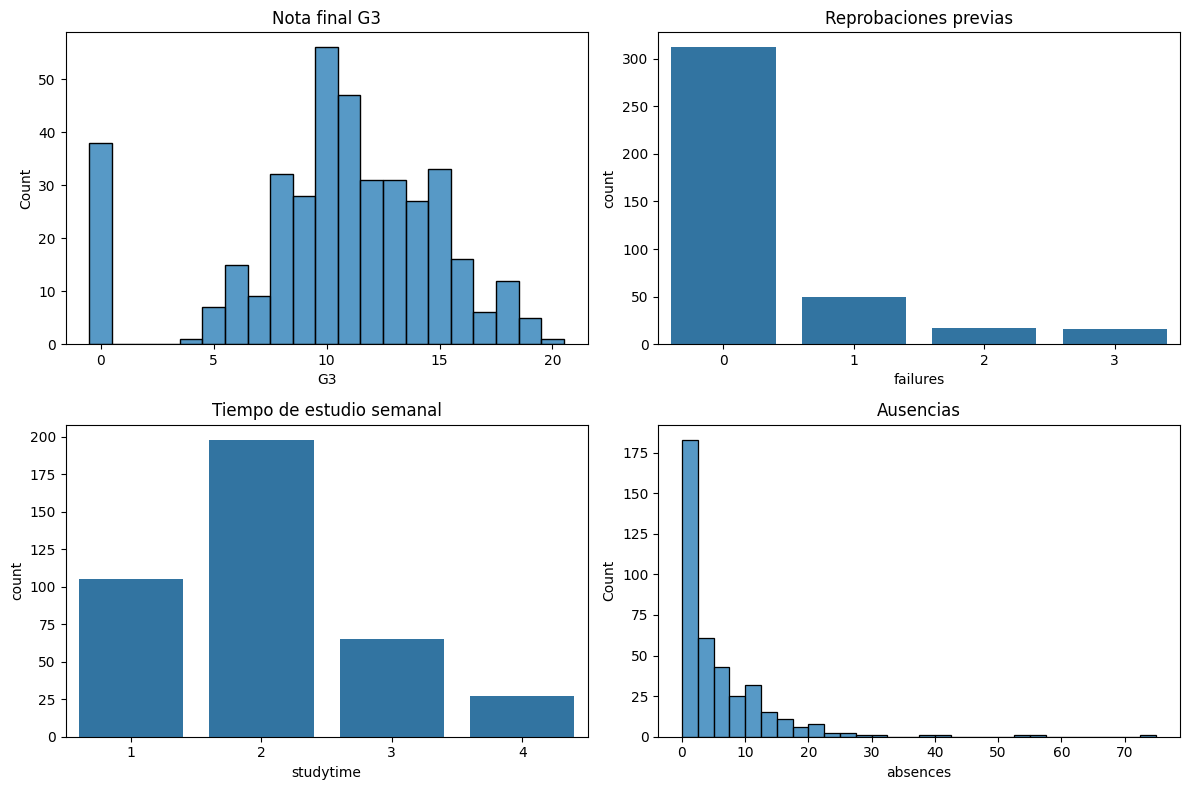

In [11]:
# Generación de 4 gráficos
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["G3"], bins=np.arange(-0.5, 21.5), ax=ax[0, 0])
ax[0, 0].set_title("Nota final G3")

sns.countplot(x="failures", data=df, ax=ax[0, 1])
ax[0, 1].set_title("Reprobaciones previas")

sns.countplot(x="studytime", data=df, ax=ax[1, 0])
ax[1, 0].set_title("Tiempo de estudio semanal")

sns.histplot(df["absences"], bins=30, ax=ax[1, 1])
ax[1, 1].set_title("Ausencias")

plt.tight_layout()  # evita que los gráficos se encimen
plt.show()

En el primer gráfico se puede ver que la mayoría de las notas finales G3 está entre 8 y 15.
El gráfico de reprobaciones previas presenta a la mayor parte de los estudiantes en 0 y muy pocos tienen 2 o 3.
El gráfico de tiempo de estudio refleja que el más común es el nivel 2, que equivale a entre 2 y 5 horas por semana, mientras que pocos estudian más de 10 horas.
El gráfico de ausencias muestra pocas ausencias ya que sus barras están concetradas en menor a 10 pero si hay algunos casos con valores muy altos que llegan hasta 75.